In [4]:
import os
import numpy as np
import pandas as pd
import librosa
import soundfile as sf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, confusion_matrix, classification_report, accuracy_score, precision_score, recall_score
import warnings
warnings.filterwarnings('ignore')

ROOT = './messy_mashup'
STEMS_PATH = os.path.join(ROOT, 'genres_stems')
GENRES = ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']
STEMS = ['bass.wav', 'drums.wav', 'other.wav', 'vocals.wav']

In [5]:
jazz_path = os.path.join(STEMS_PATH, 'jazz')
durations = []
for song in sorted(os.listdir(jazz_path)):
    for stem in STEMS:
        fpath = os.path.join(jazz_path, song, stem)
        if os.path.exists(fpath):
            durations.append(sf.info(fpath).duration)

q1_mean_duration_jazz = float(np.mean(durations))
q1_mean_duration_jazz

30.032979591836728

In [6]:
sample_rates = set()

for genre in GENRES:
    gp = os.path.join(STEMS_PATH, genre)
    for song in os.listdir(gp):
        for stem in STEMS:
            fpath = os.path.join(gp, song, stem)
            if os.path.exists(fpath):
                sample_rates.add(sf.info(fpath).samplerate)

for f in os.listdir(os.path.join(ROOT, 'ESC-50-master', 'audio')):
    try:
        sample_rates.add(sf.info(os.path.join(ROOT, 'ESC-50-master', 'audio', f)).samplerate)
    except Exception:
        pass

for f in os.listdir(os.path.join(ROOT, 'mashups')):
    if f.endswith('.wav'):
        sample_rates.add(sf.info(os.path.join(ROOT, 'mashups', f)).samplerate)

q2_unique_sample_rates = sorted(sample_rates)
q2_unique_sample_rates

[22050, 44100]

In [7]:
empty_count = 0
for genre in GENRES:
    gp = os.path.join(STEMS_PATH, genre)
    for song in os.listdir(gp):
        for stem in STEMS:
            fpath = os.path.join(gp, song, stem)
            if os.path.exists(fpath) and os.path.getsize(fpath) == 0:
                empty_count += 1

q3_empty_zero_byte_files = int(empty_count)
q3_empty_zero_byte_files

0

In [8]:
peaks_db = []
for genre in GENRES:
    gp = os.path.join(STEMS_PATH, genre)
    for song in sorted(os.listdir(gp)):
        fpath = os.path.join(gp, song, 'vocals.wav')
        if os.path.exists(fpath):
            y, sr = librosa.load(fpath, sr=None)
            peak = np.max(np.abs(y))
            if peak > 0:
                peaks_db.append(20 * np.log10(peak))

q4_avg_peak_db_vocals = float(np.mean(peaks_db))
q4_avg_peak_db_vocals

-12.49492073059082

In [9]:
genre_centroids = {}
for genre in GENRES:
    gp = os.path.join(STEMS_PATH, genre)
    centroids = []
    for song in sorted(os.listdir(gp)):
        fpath = os.path.join(gp, song, 'other.wav')
        if os.path.exists(fpath):
            y, sr = librosa.load(fpath, sr=22050, duration=10)
            centroids.append(np.mean(librosa.feature.spectral_centroid(y=y, sr=sr)))
    genre_centroids[genre] = np.mean(centroids)

sorted_genre_centroids = dict(sorted(genre_centroids.items(), key=lambda x: x[1], reverse=True))
q5_mean_spectral_centroid_blues = float(genre_centroids['blues'])
q6_highest_spectral_centroid_genre = max(genre_centroids, key=genre_centroids.get)

sorted_genre_centroids, q5_mean_spectral_centroid_blues, q6_highest_spectral_centroid_genre

({'hiphop': np.float64(2492.232935896093),
  'metal': np.float64(2441.549801968225),
  'disco': np.float64(1864.4728851565142),
  'reggae': np.float64(1721.7131323006306),
  'blues': np.float64(1627.3236221419816),
  'jazz': np.float64(1605.8017464953273),
  'pop': np.float64(1536.198328124378),
  'rock': np.float64(1521.4795765357862),
  'classical': np.float64(1359.9346659221785),
  'country': np.float64(1315.2380089567396)},
 1627.3236221419816,
 'hiphop')

In [10]:
silence_count = 0
for genre in GENRES:
    gp = os.path.join(STEMS_PATH, genre)
    for song in sorted(os.listdir(gp)):
        for stem in STEMS:
            fpath = os.path.join(gp, song, stem)
            if os.path.exists(fpath):
                y, sr = librosa.load(fpath, sr=None, duration=0.5)
                if np.max(np.abs(y)) < 1e-4:
                    silence_count += 1

q7_stems_silence_first_half_second = int(silence_count)
q7_stems_silence_first_half_second

333

In [11]:
def extract_features(song_path):
    y, sr = librosa.load(os.path.join(song_path, 'other.wav'), sr=22050, duration=10)
    tempo, _ = librosa.beat.beat_track(y=y, sr=sr)
    spec_cent = np.mean(librosa.feature.spectral_centroid(y=y, sr=sr))
    zcr = np.mean(librosa.feature.zero_crossing_rate(y))
    rolloff = np.mean(librosa.feature.spectral_rolloff(y=y, sr=sr))
    return [float(tempo), spec_cent, zcr, rolloff]

data = []
for g in GENRES:
    gp = os.path.join(STEMS_PATH, g)
    songs = [s for s in os.listdir(gp) if os.path.isdir(os.path.join(gp, s))]
    for s in songs[:50]:
        data.append({'path': os.path.join(gp, s), 'genre': g})

df = pd.DataFrame(data)
train_df, val_df = train_test_split(df, test_size=0.2, stratify=df['genre'], random_state=42)

X_train = np.array([extract_features(p) for p in train_df['path']])
y_train = train_df['genre']
X_val = np.array([extract_features(p) for p in val_df['path']])
y_val = val_df['genre']

clf = DecisionTreeClassifier(max_depth=5, random_state=42)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_val)
macro_f1 = f1_score(y_val, y_pred, average='macro')
cm = confusion_matrix(y_val, y_pred, labels=GENRES)
cr = classification_report(y_val, y_pred, labels=GENRES)
acc = accuracy_score(y_val, y_pred)

q8_macro_f1 = float(macro_f1)
q11_accuracy = float(acc)

q8_macro_f1, cr, q11_accuracy

(0.15232778165746702,
 '              precision    recall  f1-score   support\n\n       blues       0.43      0.30      0.35        10\n   classical       0.00      0.00      0.00        10\n     country       0.12      0.20      0.15        10\n       disco       0.21      0.70      0.33        10\n      hiphop       0.00      0.00      0.00        10\n        jazz       0.08      0.10      0.09        10\n       metal       0.38      0.30      0.33        10\n         pop       0.00      0.00      0.00        10\n      reggae       0.20      0.40      0.27        10\n        rock       0.00      0.00      0.00        10\n\n    accuracy                           0.20       100\n   macro avg       0.14      0.20      0.15       100\nweighted avg       0.14      0.20      0.15       100\n',
 0.2)

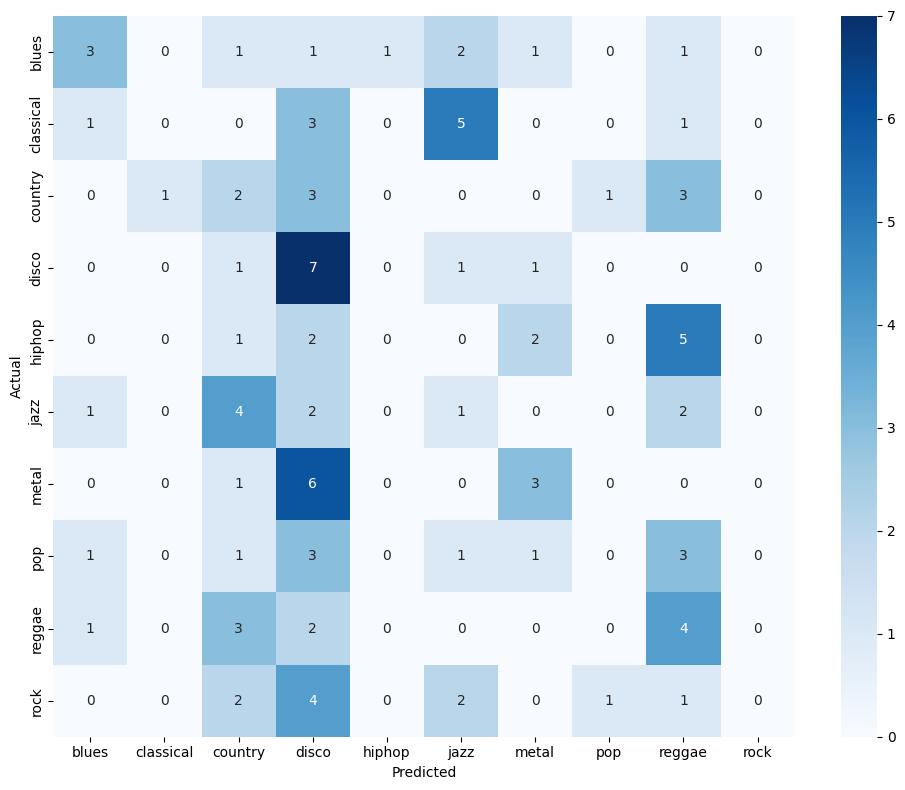

In [12]:
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=GENRES, yticklabels=GENRES)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

In [13]:
precisions = precision_score(y_val, y_pred, labels=GENRES, average=None, zero_division=0)
recalls = recall_score(y_val, y_pred, labels=GENRES, average=None, zero_division=0)

tp_dict = {}
fn_dict = {}
rows = []

for i, g in enumerate(GENRES):
    tp = cm[i, i]
    fn = np.sum(cm[i, :]) - tp
    fp = np.sum(cm[:, i]) - tp
    tn = np.sum(cm) - tp - fn - fp
    tp_dict[g] = tp
    fn_dict[g] = fn
    rows.append({
        'Genre': g,
        'TP': int(tp),
        'TN': int(tn),
        'FP': int(fp),
        'FN': int(fn),
        'Precision': float(precisions[i]),
        'Recall': float(recalls[i])
    })

per_genre_metrics = pd.DataFrame(rows)
q9_precision_hiphop = float(precisions[GENRES.index('hiphop')])
q10_recall_pop = float(recalls[GENRES.index('pop')])
q12_highest_tp_genre = max(tp_dict, key=tp_dict.get)
q13_lowest_fn_genre = min(fn_dict, key=fn_dict.get)

per_genre_metrics, q9_precision_hiphop, q10_recall_pop, q12_highest_tp_genre, q13_lowest_fn_genre

(       Genre  TP  TN  FP  FN  Precision  Recall
 0      blues   3  86   4   7   0.428571     0.3
 1  classical   0  89   1  10   0.000000     0.0
 2    country   2  76  14   8   0.125000     0.2
 3      disco   7  64  26   3   0.212121     0.7
 4     hiphop   0  89   1  10   0.000000     0.0
 5       jazz   1  79  11   9   0.083333     0.1
 6      metal   3  85   5   7   0.375000     0.3
 7        pop   0  88   2  10   0.000000     0.0
 8     reggae   4  74  16   6   0.200000     0.4
 9       rock   0  90   0  10   0.000000     0.0,
 0.0,
 0.0,
 'disco',
 'disco')